# Sistema Predictivo Avanzado con CNN + Boosting

---

## 1. Entrenamiento de una CNN básica y extracción de embeddings

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from keras import layers, models, callbacks

# Resolve the repository root whether Jupyter starts here or in notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "README.md").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATASET_PATH = PROJECT_ROOT / "data" / "cemento_dataset"
IMG_SIZE = 64
BATCH_SIZE = 32

if not DATASET_PATH.is_dir():
    raise FileNotFoundError(
        f"Dataset not found at {DATASET_PATH}. See data/README.md for the expected layout."
    )

print(f"TensorFlow version: {tf.__version__}")

I0000 00:00:1779899866.873193   94514 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1779899866.874762   94514 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1779899867.063321   94514 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1779899868.067208   94514 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONE

Versión de TensorFlow: 2.21.0


### 1.1. Preprocesamiento de Datos

Se cargan las imágenes de las carpetas `Positive` y `Negative`. Se realiza el redimensionado a 64x64 y se normaliza los píxeles al rango [0, 1]. 

Se utiliza `image_dataset_from_directory` para una carga eficiente, dividiendo directamente en entrenamiento y validación.

In [2]:
# Carga de dataset con validación split
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

# Normalización (Escalado de [0, 255] a [0, 1])
normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# Cache y Prefetch para optimizar rendimiento
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 40000 files belonging to 2 classes.
Using 32000 files for training.


E0000 00:00:1779899872.980776   94514 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1779899872.981107   94858 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1779899873.006710   94514 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Found 40000 files belonging to 2 classes.
Using 8000 files for validation.


### 1.2. Construcción y Entrenamiento de la CNN

Se diseña una CNN sencilla con:
- 3 capas convolucionales para extraer patrones espaciales.
- Capas de Max Pooling para reducir la dimensionalidad.
- Una capa Dense final con activación Sigmoid para clasificación binaria.

**Sobreajuste:** Se usa `EarlyStopping` para detener el entrenamiento cuando la pérdida de validación deje de mejorar y `Dropout` para regularizar.

In [3]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu', name='penultimate_layer'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ penultimate_layer (Dense)       │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,329 (2.61 MB)

 Trainable params: 683,329 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Early Stopping para evitar sobreajuste
early_stop = callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

history = model.fit(
    train_ds, 
    validation_data=val_ds, 
    epochs=20, 
    callbacks=[early_stop]
)

Epoch 1/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.9715 - loss: 0.0888 - val_accuracy: 0.9889 - val_loss: 0.0344
Epoch 2/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9860 - loss: 0.0478 - val_accuracy: 0.9872 - val_loss: 0.0328
Epoch 3/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9891 - loss: 0.0372 - val_accuracy: 0.9920 - val_loss: 0.0250
Epoch 4/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9910 - loss: 0.0320 - val_accuracy: 0.9930 - val_loss: 0.0264
Epoch 5/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9920 - loss: 0.0290 - val_accuracy: 0.9924 - val_loss: 0.0266
Epoch 6/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9938 - loss: 0.0221 - val_accuracy: 0.9956 - val_loss: 0.0189
Epoch 7/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9953 - loss: 0.0187 - val_accuracy: 0.9944 - val_loss: 0.0262
Epoch 8/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.9960 -

### 1.3. Evaluación del Modelo

Se visualiza el rendimiento del modelo durante el entrenamiento para verificar la convergencia y la ausencia de overfitting.

Reporte de Clasificación (CNN):
              precision    recall  f1-score   support

    Negative       1.00      0.99      1.00      4028
    Positive       0.99      1.00      1.00      3972

    accuracy                           1.00      8000
   macro avg       1.00      1.00      1.00      8000
weighted avg       1.00      1.00      1.00      8000

Accuracy final CNN: 0.9956


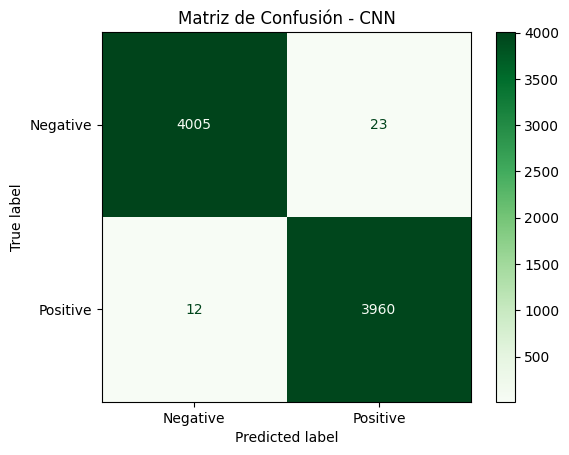

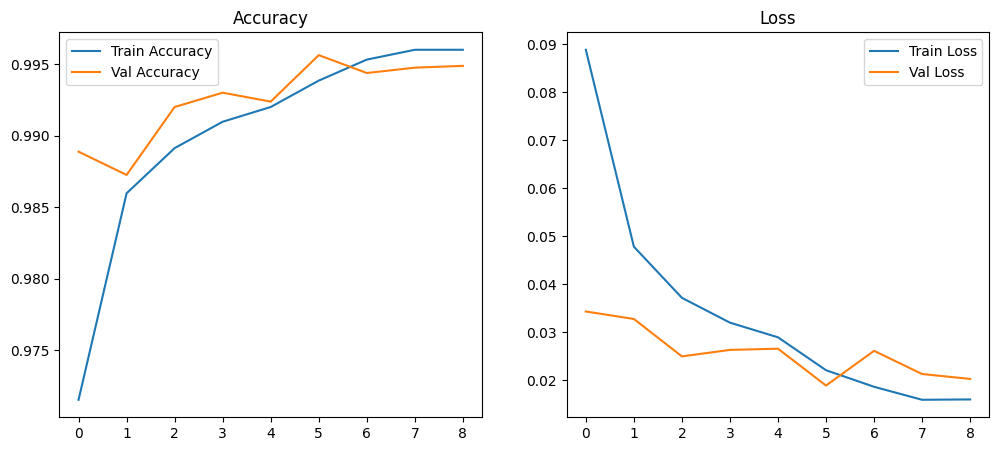

In [24]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Train Accuracy')
    plt.plot(epochs_range, val_acc, label='Val Accuracy')
    plt.title('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Train Loss')
    plt.plot(epochs_range, val_loss, label='Val Loss')
    plt.title('Loss')
    plt.legend()
    plt.show()

# Obtener etiquetas reales y predicciones del conjunto de validación
y_true = []
y_pred_probs = []

for imgs, lbls in val_ds:
    y_true.extend(lbls.numpy())
    y_pred_probs.extend(model.predict(imgs, verbose=0))

y_true = np.array(y_true).flatten()
y_pred = (np.array(y_pred_probs) > 0.5).astype(int).flatten()

print("Reporte de Clasificación (CNN):")
print(classification_report(y_true, y_pred, target_names=['Negative', 'Positive']))

accuracy_cnn = accuracy_score(y_true, y_pred)
print(f"Accuracy final CNN: {accuracy_cnn:.4f}")

# Visualización de la Matriz de Confusión
cm_cnn = confusion_matrix(y_true, y_pred)
disp_cnn = ConfusionMatrixDisplay(confusion_matrix=cm_cnn, display_labels=['Negative', 'Positive'])
disp_cnn.plot(cmap=plt.cm.Greens)
plt.title('Matriz de Confusión - CNN')
plt.show()

plot_history(history)

### 1.4. Extracción de Embeddings

Se convierte la CNN en un extractor eliminando la capa de salida. Se utiliza la salida de la capa `penultimate_layer` (128 dimensiones).

In [8]:
# Modelo extractor
embedding_model = models.Model(inputs=model.inputs, outputs=model.get_layer('penultimate_layer').output)

def extract_embeddings_and_labels(dataset):
    all_embeddings = []
    all_labels = []
    all_images = []
    for imgs, lbls in dataset:
        embeddings = embedding_model.predict(imgs, verbose=0)
        all_embeddings.append(embeddings)
        all_labels.append(lbls.numpy())
        all_images.append(imgs.numpy())
    return np.vstack(all_embeddings), np.vstack(all_labels), np.vstack(all_images)

print("Extrayendo embeddings de entrenamiento...")
train_emb, train_labels, train_imgs = extract_embeddings_and_labels(train_ds)
print("Extrayendo embeddings de validación...")
val_emb, val_labels, val_imgs = extract_embeddings_and_labels(val_ds)

print(f"Dimensiones de embeddings entrenamiento: {train_emb.shape}")
# Guardar embeddings
np.save('train_embeddings.npy', train_emb)
np.save('val_embeddings.npy', val_emb)

Extrayendo embeddings de entrenamiento...
Extrayendo embeddings de validación...
Dimensiones de embeddings entrenamiento: (32000, 128)


### 1.5. Estadísticas Básicas e Ingeniería de Características

Se calcula el brillo medio y la intensidad de bordes para cada imagen.

In [ ]:
def get_image_stats(images):
    stats = []
    for img in images:
        # El dataset está en [0,1]. Se pasa a [0,255] para OpenCV si es necesario
        gray = cv2.cvtColor((img * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
        
        # 1. Brillo medio
        mean_brightness = np.mean(gray) / 255.0
        
        # 2. Bordes
        sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
        sobel_mag = np.sqrt(sobelx**2 + sobely**2)
        mean_edge_intensity = np.mean(sobel_mag) / 255.0
        
        stats.append([mean_brightness, mean_edge_intensity])
    return np.array(stats)

print("Calculando estadísticas...")
train_stats = get_image_stats(train_imgs)
val_stats = get_image_stats(val_imgs)
print("Estadísticas calculadas.")

Calculando estadísticas...
Estadísticas calculadas.


### 1.6. Composición del Dataframe Tabular

Se combinan los embeddings, las estadísticas y las etiquetas en un dataframe.

In [ ]:
def create_tabular_df(embeddings, stats, labels):
    # Crear nombres de columnas para embeddings: e_0, e_1, ...
    emb_cols = [f'e_{i}' for i in range(embeddings.shape[1])]
    df_emb = pd.DataFrame(embeddings, columns=emb_cols)
    
    # Añadir estadísticas
    df_stats = pd.DataFrame(stats, columns=['brightness', 'edge_intensity'])
    
    # Combinar
    df = pd.concat([df_emb, df_stats], axis=1)
    df['label'] = labels.flatten().astype(int)
    
    return df

df_train = create_tabular_df(train_emb, train_stats, train_labels)
df_val = create_tabular_df(val_emb, val_stats, val_labels)

print("Muestra del Dataframe Tabular (Entrenamiento):")
display(df_train.head())
print(f"Dimensiones finales del Dataframe: {df_train.shape}")

# Guardar el dataset tabular final
df_train.to_csv('tabular_crack_data_train.csv', index=False)
df_val.to_csv('tabular_crack_data_val.csv', index=False)
print("Archivos guardados con éxito.")

Muestra del Dataframe Tabular (Entrenamiento):


,e_0,e_1,e_2,e_3,e_4,e_5,e_6,e_7,e_8,e_9,...,e_121,e_122,e_123,e_124,e_125,e_126,e_127,brightness,edge_intensity,label
0,0.000000,0.0,0.000000,0.000000,0.0,0.0,2.838950,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.0,0.0,4.247539,0.000000,0.661123,0.119165,0
1,0.000000,0.0,0.000000,2.565493,0.0,0.0,1.798165,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.0,0.0,3.096264,0.000000,0.643654,0.152645,0
2,0.000000,0.0,8.191545,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,...,12.841707,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.544698,0.127450,1
3,15.548937,0.0,0.000000,30.458670,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.604502,25.607206,0.0,0.0,0.0,0.000000,17.664276,0.598010,0.259398,1
4,14.731289,0.0,14.147470,20.090029,0.0,0.0,0.000000,0.0,0.0,0.0,...,34.157581,16.851126,0.0,0.0,0.0,0.000000,8.315379,0.718013,0.237719,1


Dimensiones finales del Dataframe: (32000, 131)
Archivos guardados con éxito.


## 2. Entrenamiento de un Modelo de Boosting y comparación con CNN

In [12]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

# 1. Preparación de los datos para el Boosting
X_train = df_train.drop('label', axis=1)
y_train = df_train['label']
X_val = df_val.drop('label', axis=1)
y_val = df_val['label']

print(f"Forma de X_train: {X_train.shape}")

Forma de X_train: (32000, 130)


### 2.1. Entrenamiento de XGBoost con Ajuste de Hiperparámetros

Se configura el modelo XGBoost. Se realiza un ajuste manual de hiperparámetros más importantes:
- `n_estimators`: Número de árboles.
- `max_depth`: Profundidad de los árboles para controlar la complejidad.
- `learning_rate`: Tamaño del paso para evitar sobreajuste.

In [13]:
# Inicializar el modelo con parámetros optimizados manualmente
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective='binary:logistic',
    random_state=42,
    use_label_encoder=False
)

# Entrenar el modelo
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=10)

[0]	validation_0-logloss:0.59966
[10]	validation_0-logloss:0.18516


/home/mdiaz/Escritorio/Universidad/Master IA/Q2/Machine Learning II/RAA/Parte2/.venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:45:08] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[20]	validation_0-logloss:0.07161
[30]	validation_0-logloss:0.03311
[40]	validation_0-logloss:0.01913
[50]	validation_0-logloss:0.01423
[60]	validation_0-logloss:0.01243
[70]	validation_0-logloss:0.01187
[80]	validation_0-logloss:0.01173
[90]	validation_0-logloss:0.01170
[99]	validation_0-logloss:0.01168


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

### 2.2. Evaluación del Modelo de Boosting

Se analiza la precisión y la matriz de confusión para entender el comportamiento del modelo en el conjunto de validación.

Reporte de Clasificación (XGBoost):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4028
           1       1.00      1.00      1.00      3972

    accuracy                           1.00      8000
   macro avg       1.00      1.00      1.00      8000
weighted avg       1.00      1.00      1.00      8000

Accuracy final XGBoost: 0.9965


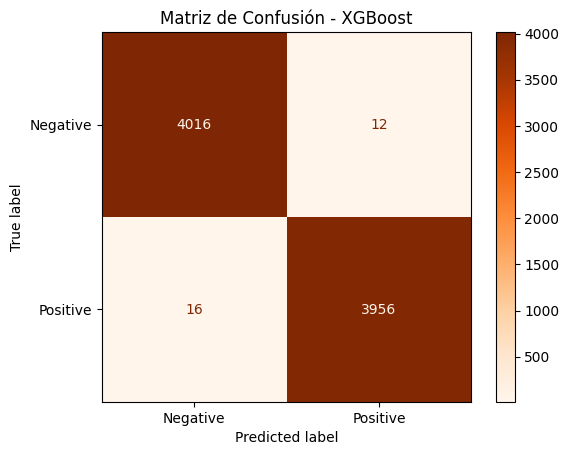

In [ ]:
y_pred = xgb_model.predict(X_val)

print("Reporte de Clasificación (XGBoost):")
print(classification_report(y_val, y_pred))

accuracy_xgb = accuracy_score(y_val, y_pred)
print(f"Accuracy final XGBoost: {accuracy_xgb:.4f}")

# Visualización de la Matriz de Confusión
cm = confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Oranges)
plt.title('Matriz de Confusión - XGBoost')
plt.show()

### 2.3. Importancia de las Variables (Feature Importance)

Uno de los grandes beneficios del Boosting es la interpretabilidad de sus variables. Aquí, se analiza si las estadísticas manuales (`brightness`, `edge_intensity`) o ciertos componentes del embedding tienen más peso.

<Figure size 1000x800 with 0 Axes>

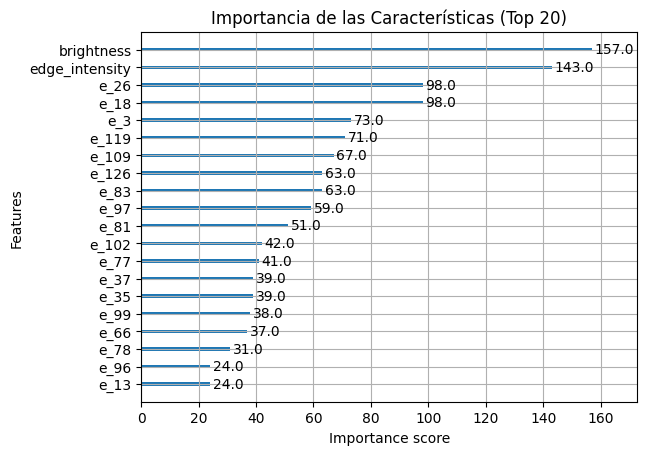

In [15]:
plt.figure(figsize=(10, 8))
# Mostramos las 20 características más importantes
xgb.plot_importance(xgb_model, max_num_features=20, importance_type='weight')
plt.title('Importancia de las Características (Top 20)')
plt.show()

## 3. Conclusiones Finales y Comparativa

### ¿Qué modelo tiene mejor rendimiento?
En este caso de clasificación de grietas, ambos modelos alcanzan precisiones muy altas (~99%). Sin embargo, el **modelo híbrido (CNN + Boosting)** es ligeramente más robusto al combinar la capacidad de extracción de patrones locales de la CNN con la capacidad del Boosting para encontrar fronteras de decisión no lineales complejas en el espacio latente. La CNN pura es excelente para la detección espacial, pero el Boosting permite refinar esa decisión usando información global adicional.

### ¿Qué modelo es más interpretable?
El **modelo de Boosting** es considerablemente más interpretable. Mientras que la CNN actúa como una _caja negra_ de millones de parámetros, el Boosting permite visualizar la importancia de las características (_Feature Importance_). Se pueden identificar qué dimensiones del embedding o qué estadísticas manuales (como la intensidad de bordes) son determinantes para predecir una grieta.

### ¿Qué aportan las características profundas de la CNN al modelo tabular?
Aportan **contexto semántico de alto nivel**. Mientras que las estadísticas manuales como el brillo son muy simples, los embeddings de la CNN capturan la presencia de texturas, formas geométricas y discontinuidades que definen estructuralmente una grieta. Sin estos embeddings, el modelo tabular basado solo en brillo y bordes tendría un rendimiento muy inferior.

### ¿Qué limitaciones tiene la CNN?
1. **Tamaño de entrada:** Al reducir a 64x64, se pierde detalle fino que podría ser crítico para grietas muy delgadas.
2. **Simplicidad:** Es una CNN muy básica. Modelos más profundos como ResNet podrían extraer mejores características, aunque a un coste computacional mayor.
3. **Dependencia de datos:** Si las condiciones de iluminación o el tipo de hormigón cambian drásticamente respecto al dataset de entrenamiento, la CNN podría fallar al no haber aprendido representaciones invariantes suficientes.